# Rossmann Christmas Footfall Prediction  
## Stage 2 — Python Data Pre-processing

This notebook implements the preprocessing workflow required by the assignment in Python.

### Business objective
Predict whether an open Rossmann store will experience **unusually high customer footfall during the Christmas shopping period (1–24 December)**.

### Key preprocessing principles
- Merge `train.csv` and `store.csv`.
- Exclude closed stores from demand modelling.
- Treat Promo2 missingness as structural rather than random.
- Engineer Christmas and competition features.
- Avoid leakage from same-day `Sales` and `Customers`.
- Create a store-specific `High_Footfall` target.
- Use a chronological split: Christmas 2013 for training and Christmas 2014 for testing.
- Encode categorical variables and scale numeric variables for ML-ready matrices.


In [1]:
# 1. Import libraries
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')


In [37]:

# 2. Load the COMPLETE Rossmann files
import pandas as pd

train_path = "/content/train.csv"
store_path = "/content/store.csv"

train = pd.read_csv(train_path, low_memory=False)
store = pd.read_csv(store_path, low_memory=False)

source_dates = pd.to_datetime(train["Date"], errors="raise")

assert source_dates.notna().all(), "The source contains missing dates."
assert {2013, 2014}.issubset(set(source_dates.dt.year)), (
    "This file does not contain both 2013 and 2014. "
    "Upload the complete train.csv supplied in this conversation."
)

print("train.csv shape:", train.shape)
print("store.csv shape:", store.shape)
print("Date range:", source_dates.min().date(), "to", source_dates.max().date())

display(source_dates.dt.year.value_counts().sort_index().rename("Rows"))

train.csv shape: (1017209, 9)
store.csv shape: (1115, 10)
Date range: 2013-01-01 to 2015-07-31


,Rows
Date,
2013,406974
2014,373855
2015,236380


In [39]:
# 3. Inspect data types, duplicates, and missing values
print('Duplicate rows in train.csv:', train.duplicated().sum())
print('Duplicate rows in store.csv:', store.duplicated().sum())

print('\ntrain.csv data types:')
display(train.dtypes.to_frame('dtype'))

print('\nMissing values in store.csv:')
missing_store = pd.DataFrame({
    'Missing_Count': store.isna().sum(),
    'Missing_Percent': store.isna().mean() * 100
}).sort_values('Missing_Percent', ascending=False)

display(missing_store[missing_store['Missing_Count'] > 0])


Duplicate rows in train.csv: 0
Duplicate rows in store.csv: 0

train.csv data types:


,dtype
Store,int64
DayOfWeek,int64
Date,object
Sales,int64
Customers,int64
Open,int64
Promo,int64
StateHoliday,object
SchoolHoliday,int64



Missing values in store.csv:


,Missing_Count,Missing_Percent
PromoInterval,544,48.789
Promo2SinceYear,544,48.789
Promo2SinceWeek,544,48.789
CompetitionOpenSinceYear,354,31.749
CompetitionOpenSinceMonth,354,31.749
CompetitionDistance,3,0.269


In [40]:
# 4. Convert Date and merge the two datasets
train['Date'] = pd.to_datetime(train['Date'])

df = train.merge(store, on='Store', how='left', validate='many_to_one')

print('Merged dataset shape:', df.shape)
print('Unmatched stores after merge:', df['StoreType'].isna().sum())
display(df.head())


Merged dataset shape: (1017209, 18)
Unmatched stores after merge: 0


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,"1,270.000",9.000,"2,008.000",0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.000,11.000,"2,007.000",1,13.000,"2,010.000","Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,"14,130.000",12.000,"2,006.000",1,14.000,"2,011.000","Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.000,9.000,"2,009.000",0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,"29,910.000",4.000,"2,015.000",0,NaN,NaN,NaN


In [41]:
# 5. Basic calendar feature engineering
# Ensure we clean up invalid/NaN Date values first
df = df.dropna(subset=['Date']).copy()

df['Year'] = df['Date'].dt.year.astype(int)
df['Month'] = df['Date'].dt.month.astype(int)
df['Day'] = df['Date'].dt.day.astype(int)

# Safely parse DaysToChristmas
clean_years = df['Year'].astype(str)
christmas_date = pd.to_datetime(clean_years + '-12-25', format='%Y-%m-%d', errors='coerce')
df['DaysToChristmas'] = (christmas_date - df['Date']).dt.days.astype(int)

print("Unique Years available in df:", df['Year'].unique())
display(df[['Date', 'Year', 'Month', 'Day', 'DaysToChristmas']].head())

Unique Years available in df: [2015 2014 2013]


,Date,Year,Month,Day,DaysToChristmas
0,2015-07-31,2015,7,31,147
1,2015-07-31,2015,7,31,147
2,2015-07-31,2015,7,31,147
3,2015-07-31,2015,7,31,147
4,2015-07-31,2015,7,31,147


In [42]:
# 6. Create competition-related features

# Competition information is partly missing. Rather than inventing dates,
# create an explicit indicator showing whether the opening date is known.
df['CompetitionHistoryKnown'] = (
    df['CompetitionOpenSinceYear'].notna() &
    df['CompetitionOpenSinceMonth'].notna()
).astype(int)

# Compute competitor opening date where known
comp_year = df['CompetitionOpenSinceYear'].fillna(2000).astype(int)
comp_month = df['CompetitionOpenSinceMonth'].fillna(1).astype(int)

competition_open_date = pd.to_datetime(
    dict(year=comp_year, month=comp_month, day=1),
    errors='coerce'
)

# Months since competitor opened; unknown values remain NaN for now.
df['CompetitionAgeMonths'] = (
    (df['Date'].dt.year - competition_open_date.dt.year) * 12
    + (df['Date'].dt.month - competition_open_date.dt.month)
)

df.loc[df['CompetitionHistoryKnown'] == 0, 'CompetitionAgeMonths'] = np.nan

# A negative age would mean the recorded competitor opening date is in the future
# relative to the observation, so the competitor was not yet open.
df['CompetitionActive'] = (
    (df['CompetitionHistoryKnown'] == 1) &
    (df['CompetitionAgeMonths'] >= 0)
).astype(int)

df.loc[df['CompetitionAgeMonths'] < 0, 'CompetitionAgeMonths'] = 0

display(df[['CompetitionDistance','CompetitionHistoryKnown',
            'CompetitionAgeMonths','CompetitionActive']].head(10))


,CompetitionDistance,CompetitionHistoryKnown,CompetitionAgeMonths,CompetitionActive
0,"1,270.000",1,82.000,1
1,570.000,1,92.000,1
2,"14,130.000",1,103.000,1
3,620.000,1,70.000,1
4,"29,910.000",1,3.000,1
5,310.000,1,19.000,1
6,"24,000.000",1,27.000,1
7,"7,520.000",1,9.000,1
8,"2,030.000",1,179.000,1
9,"3,160.000",1,70.000,1


In [43]:
# 7. Treat Promo2 structural missingness and engineer Promo2Active

# Check whether missing Promo2 fields are structurally tied to Promo2 = 0
promo2_check = (
    df.groupby('Promo2')[['Promo2SinceWeek','Promo2SinceYear','PromoInterval']]
      .apply(lambda x: x.isna().mean() * 100)
)

print('Percentage missing in Promo2 fields by Promo2 status:')
display(promo2_check)

month_names = {
    1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr', 5:'May', 6:'Jun',
    7:'Jul', 8:'Aug', 9:'Sept', 10:'Oct', 11:'Nov', 12:'Dec'
}

df['MonthNameForPromo2'] = df['Month'].map(month_names)

# Promo2Active requires:
# 1) store participates in Promo2,
# 2) current month is listed in PromoInterval,
# 3) observation occurs after Promo2 start.
promo2_start_year = df['Promo2SinceYear'].fillna(9999).astype(int)
promo2_start_week = df['Promo2SinceWeek'].fillna(1).astype(int)

# approximate first day of ISO promo week
promo2_start_str = (
    promo2_start_year.astype(str) + '-W' +
    promo2_start_week.astype(str).str.zfill(2) + '-1'
)
promo2_start_date = pd.to_datetime(promo2_start_str, format='%G-W%V-%u', errors='coerce')

month_is_active = df.apply(
    lambda r: (
        isinstance(r['PromoInterval'], str)
        and r['MonthNameForPromo2'] in r['PromoInterval'].split(',')
    ),
    axis=1
)

df['Promo2Active'] = (
    (df['Promo2'] == 1) &
    month_is_active &
    (df['Date'] >= promo2_start_date)
).astype(int)

print('Promo2 participation rate:', round(df['Promo2'].mean(), 3))
print('Promo2 active rate:', round(df['Promo2Active'].mean(), 3))


Percentage missing in Promo2 fields by Promo2 status:


,Promo2SinceWeek,Promo2SinceYear,PromoInterval
Promo2,,,
0,100.000,100.000,100.000
1,0.000,0.000,0.000


Promo2 participation rate: 0.501
Promo2 active rate: 0.149


In [44]:
# 8. Define the Christmas modelling window

christmas = df[
    df['Year'].isin([2013, 2014]) &
    (df['Month'] == 12) &
    (df['Day'] <= 24)
].copy()

print('Christmas observations before removing closed stores:', len(christmas))
print('Closed-store observations:', (christmas['Open'] == 0).sum())

# Closed stores are excluded because zero customers are operationally caused by closure,
# not by low customer demand.
christmas_open = christmas[christmas['Open'] == 1].copy()

print('Christmas observations after keeping open stores:', len(christmas_open))
display(
    christmas_open.groupby('Year')['Customers']
    .agg(['count','mean','median','min','max'])
)


Christmas observations before removing closed stores: 49200
Closed-store observations: 7126
Christmas observations after keeping open stores: 42074


,count,mean,median,min,max
Year,,,,,
2013,22380,913.481,801.000,61,4916
2014,19694,913.055,809.000,102,4962


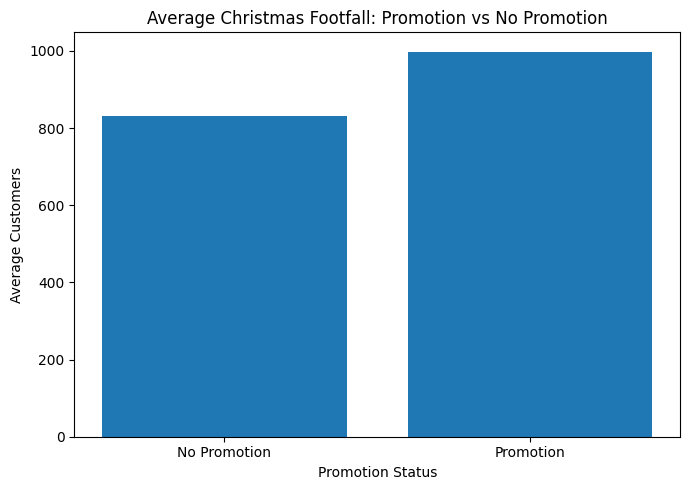

,count,mean,median
Promo,,,
0,21574,832.553,708.000
1,20500,998.239,893.000


In [45]:
# Exploratory Data Analysis (EDA)
import matplotlib.pyplot as plt

promo_eda = (
    christmas_open
    .groupby('Promo')['Customers']
    .mean()
    .reset_index()
)

promo_eda['Promo_Label'] = promo_eda['Promo'].map({
    0: 'No Promotion',
    1: 'Promotion'
})

plt.figure(figsize=(7, 5))
plt.bar(promo_eda['Promo_Label'], promo_eda['Customers'])
plt.title('Average Christmas Footfall: Promotion vs No Promotion')
plt.xlabel('Promotion Status')
plt.ylabel('Average Customers')
plt.tight_layout()
plt.show()

display(
    christmas_open.groupby('Promo')['Customers']
    .agg(['count', 'mean', 'median'])
)

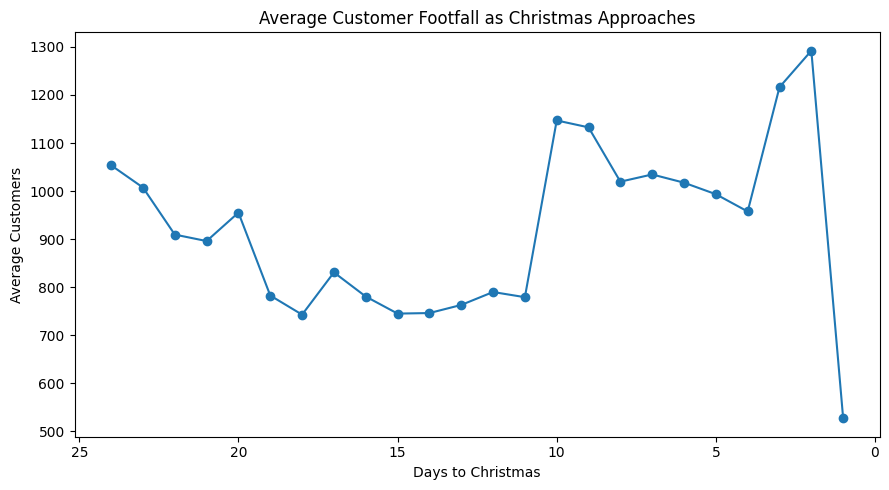

In [46]:
# Recalculate christmas_open with the newly engineered DaysToChristmas column included
christmas = df[
    df['Year'].isin([2013, 2014]) &
    (df['Month'] == 12) &
    (df['Day'] <= 24)
].copy()
christmas_open = christmas[christmas['Open'] == 1].copy()

days_to_xmas_eda = (
    christmas_open
    .groupby('DaysToChristmas')['Customers']
    .mean()
    .reset_index()
    .sort_values('DaysToChristmas')
)

plt.figure(figsize=(9, 5))
plt.plot(
    days_to_xmas_eda['DaysToChristmas'],
    days_to_xmas_eda['Customers'],
    marker='o'
)

plt.gca().invert_xaxis()

plt.title('Average Customer Footfall as Christmas Approaches')
plt.xlabel('Days to Christmas')
plt.ylabel('Average Customers')
plt.tight_layout()
plt.show()

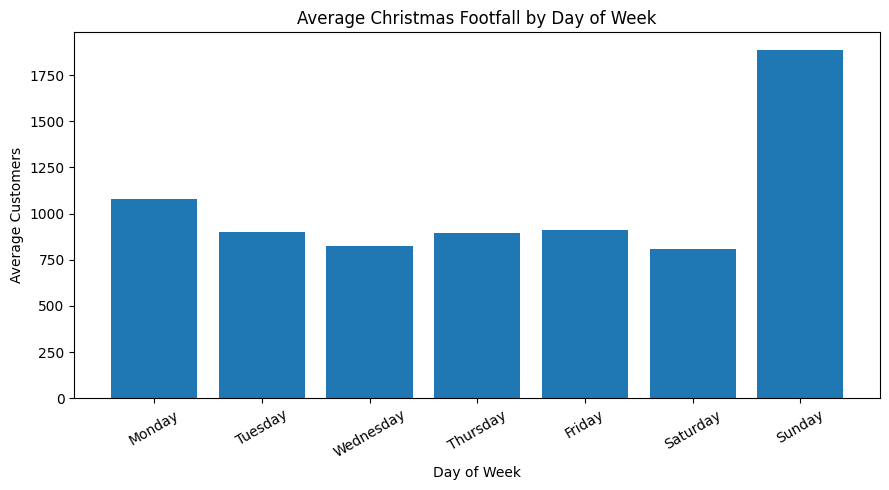

,Day,count,mean,median
0,Monday,8200,"1,077.822",974.000
1,Tuesday,8200,901.596,803.500
2,Wednesday,7085,826.443,727.000
3,Thursday,6150,895.263,797.000
4,Friday,6150,909.772,807.000
5,Saturday,6150,809.031,689.000
6,Sunday,139,"1,887.309","1,724.000"


In [47]:
day_names = {
    1: 'Monday',
    2: 'Tuesday',
    3: 'Wednesday',
    4: 'Thursday',
    5: 'Friday',
    6: 'Saturday',
    7: 'Sunday'
}

dow_eda = (
    christmas_open
    .groupby('DayOfWeek')['Customers']
    .agg(['count', 'mean', 'median'])
    .reset_index()
)

dow_eda['Day'] = dow_eda['DayOfWeek'].map(day_names)

plt.figure(figsize=(9, 5))
plt.bar(dow_eda['Day'], dow_eda['mean'])

plt.title('Average Christmas Footfall by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Customers')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(dow_eda[['Day', 'count', 'mean', 'median']])

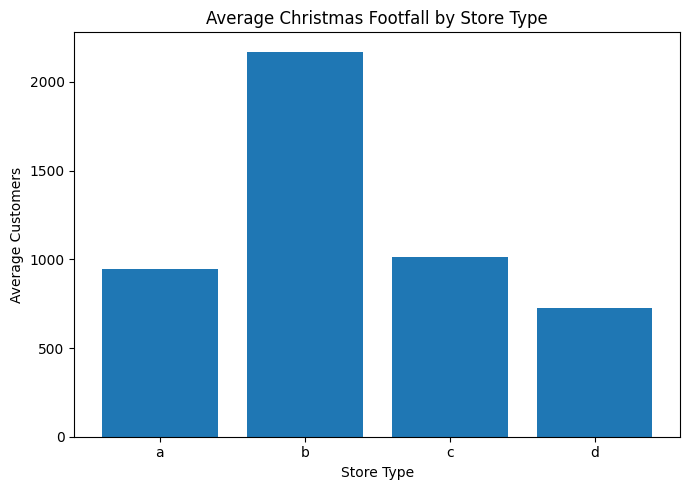

,StoreType,count,mean,median
0,a,22939,947.166,848.000
1,b,792,"2,171.101","1,900.000"
2,c,5774,"1,012.865",928.000
3,d,12569,726.436,684.000


In [48]:
storetype_eda = (
    christmas_open
    .groupby('StoreType')['Customers']
    .agg(['count', 'mean', 'median'])
    .reset_index()
)

plt.figure(figsize=(7, 5))
plt.bar(storetype_eda['StoreType'], storetype_eda['mean'])

plt.title('Average Christmas Footfall by Store Type')
plt.xlabel('Store Type')
plt.ylabel('Average Customers')
plt.tight_layout()
plt.show()

display(storetype_eda)

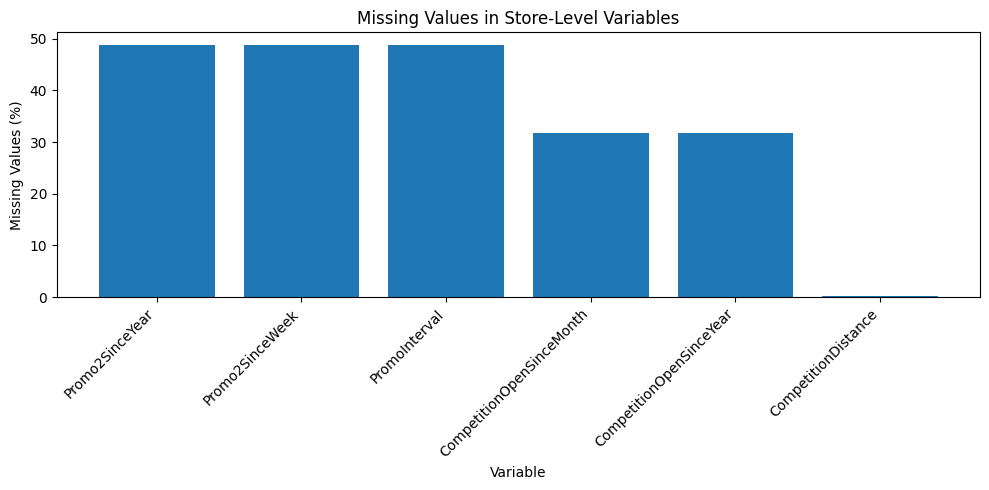

,Missing_Count,Missing_Percent
Promo2SinceYear,544,48.789
Promo2SinceWeek,544,48.789
PromoInterval,544,48.789
CompetitionOpenSinceMonth,354,31.749
CompetitionOpenSinceYear,354,31.749
CompetitionDistance,3,0.269


In [49]:
missing_eda = pd.DataFrame({
    'Missing_Count': store.isnull().sum(),
    'Missing_Percent': store.isnull().mean() * 100
})

missing_eda = (
    missing_eda[missing_eda['Missing_Count'] > 0]
    .sort_values('Missing_Percent', ascending=False)
)

plt.figure(figsize=(10, 5))
plt.bar(
    missing_eda.index,
    missing_eda['Missing_Percent']
)

plt.title('Missing Values in Store-Level Variables')
plt.xlabel('Variable')
plt.ylabel('Missing Values (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

display(missing_eda)

In [50]:
# 9. Create a leakage-safe store-specific High_Footfall target

# For each year, calculate each store's 75th percentile using Jan-Nov history only.
# This means the threshold is based only on data available before that year's December.

history = df[
    df['Year'].isin([2013, 2014]) &
    (df['Month'] <= 11) &
    (df['Open'] == 1)
].copy()

store_thresholds = (
    history.groupby(['Year','Store'])['Customers']
    .quantile(0.75)
    .rename('Store_P75_Customers')
    .reset_index()
)

christmas_open = christmas_open.merge(
    store_thresholds,
    on=['Year','Store'],
    how='left',
    validate='many_to_one'
)

print('Rows missing a historical threshold:', christmas_open['Store_P75_Customers'].isna().sum())

christmas_open['High_Footfall'] = (
    christmas_open['Customers'] > christmas_open['Store_P75_Customers']
).astype(int)

class_balance = (
    christmas_open.groupby('Year')['High_Footfall']
    .agg(['count','mean'])
    .rename(columns={'mean':'High_Footfall_Rate'})
)

display(class_balance)

print('\nOverall target distribution:')
display(
    christmas_open['High_Footfall']
    .value_counts()
    .rename_axis('High_Footfall')
    .to_frame('Count')
    .assign(Percent=lambda x: x['Count'] / x['Count'].sum() * 100)
)


Rows missing a historical threshold: 0


,count,High_Footfall_Rate
Year,,
2013,22380,0.605
2014,19694,0.582



Overall target distribution:


,Count,Percent
High_Footfall,,
1,24996,59.410
0,17078,40.590


In [51]:
# 10. Select model features and explicitly remove leakage variables

# Re-build christmas_open directly using the freshly cleaned and cast df to guarantee year integer alignment
christmas = df[
    df['Year'].isin([2013, 2014]) &
    (df['Month'] == 12) &
    (df['Day'] <= 24)
].copy()
christmas_open = christmas[christmas['Open'] == 1].copy()

# Re-apply the store threshold merge to ensure we have the target 'High_Footfall'
if 'Store_P75_Customers' not in christmas_open.columns:
    christmas_open = christmas_open.merge(
        store_thresholds,
        on=['Year','Store'],
        how='left',
        validate='many_to_one'
    )
christmas_open['High_Footfall'] = (
    christmas_open['Customers'] > christmas_open['Store_P75_Customers']
).astype(int)

numeric_features = [
    'Promo',
    'SchoolHoliday',
    'CompetitionDistance',
    'CompetitionAgeMonths',
    'CompetitionHistoryKnown',
    'CompetitionActive',
    'Promo2',
    'Promo2Active',
    'DaysToChristmas'
]

categorical_features = [
    'DayOfWeek',
    'StateHoliday',
    'StoreType',
    'Assortment'
]

model_features = numeric_features + categorical_features

X = christmas_open[model_features].copy()
y = christmas_open['High_Footfall'].copy()

print('Selected model features:')
print(model_features)

print('\nVariables intentionally excluded from prediction:')
print(['Customers', 'Sales', 'Store', 'Open', 'Date', 'Store_P75_Customers'])

Selected model features:
['Promo', 'SchoolHoliday', 'CompetitionDistance', 'CompetitionAgeMonths', 'CompetitionHistoryKnown', 'CompetitionActive', 'Promo2', 'Promo2Active', 'DaysToChristmas', 'DayOfWeek', 'StateHoliday', 'StoreType', 'Assortment']

Variables intentionally excluded from prediction:
['Customers', 'Sales', 'Store', 'Open', 'Date', 'Store_P75_Customers']


In [52]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [53]:
# 11. Restore the agreed chronological train-test split
# Training: open-store observations, 1–24 December 2013
# Testing:  open-store observations, 1–24 December 2014

assert christmas_open["Store_P75_Customers"].notna().all(), (
    "Some observations have no historical threshold. "
    "Check target construction before modelling."
)

train_mask = christmas_open["Year"].eq(2013)
test_mask = christmas_open["Year"].eq(2014)

X_train = christmas_open.loc[train_mask, model_features].copy()
y_train = christmas_open.loc[train_mask, "High_Footfall"].copy()

X_test = christmas_open.loc[test_mask, model_features].copy()
y_test = christmas_open.loc[test_mask, "High_Footfall"].copy()

assert len(X_train) > 0 and len(X_test) > 0
assert christmas_open.loc[train_mask, "Date"].max() < (
    christmas_open.loc[test_mask, "Date"].min()
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

display(pd.DataFrame({
    "Dataset": ["Christmas 2013 — training", "Christmas 2014 — testing"],
    "Rows": [len(X_train), len(X_test)],
    "High_Footfall_Rate": [y_train.mean(), y_test.mean()]
}))

Training shape: (22380, 13)
Testing shape: (19694, 13)


,Dataset,Rows,High_Footfall_Rate
0,Christmas 2013 — training,22380,0.605
1,Christmas 2014 — testing,19694,0.582


In [54]:
# 12. Build the preprocessing transformer

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print('Processed training matrix shape:', X_train_processed.shape)
print('Processed test matrix shape:', X_test_processed.shape)
print('Number of final model columns:', len(feature_names))

display(pd.DataFrame({
    'Processed_Feature': feature_names
}).head(30))

Processed training matrix shape: (22380, 24)
Processed test matrix shape: (19694, 24)
Number of final model columns: 24


,Processed_Feature
0,num__Promo
1,num__SchoolHoliday
2,num__CompetitionDistance
3,num__CompetitionAgeMonths
4,num__CompetitionHistoryKnown
5,num__CompetitionActive
6,num__Promo2
7,num__Promo2Active
8,num__DaysToChristmas
9,cat__DayOfWeek_1


In [55]:
# 13. Verify that preprocessing produced no missing values

train_missing_after = np.isnan(X_train_processed).sum()
test_missing_after = np.isnan(X_test_processed).sum()

print('Missing values after preprocessing - train:', train_missing_after)
print('Missing values after preprocessing - test:', test_missing_after)

assert train_missing_after == 0
assert test_missing_after == 0

print('\nPreprocessing verification passed.')


Missing values after preprocessing - train: 0
Missing values after preprocessing - test: 0

Preprocessing verification passed.


In [56]:
# 14. Save useful cleaned outputs for later modelling

# Create the interpretable, unencoded modelling datasets
train_output = christmas_open.loc[
    train_mask,
    model_features + ['High_Footfall']
].copy()

test_output = christmas_open.loc[
    test_mask,
    model_features + ['High_Footfall']
].copy()

# Save files in Google Colab
train_output.to_csv(
    '/content/rossmann_christmas_train_clean.csv',
    index=False
)

test_output.to_csv(
    '/content/rossmann_christmas_test_clean.csv',
    index=False
)

pd.DataFrame({
    'Processed_Feature': feature_names
}).to_csv(
    '/content/rossmann_processed_feature_names.csv',
    index=False
)

print('Saved:')
print('/content/rossmann_christmas_train_clean.csv')
print('/content/rossmann_christmas_test_clean.csv')
print('/content/rossmann_processed_feature_names.csv')

Saved:
/content/rossmann_christmas_train_clean.csv
/content/rossmann_christmas_test_clean.csv
/content/rossmann_processed_feature_names.csv


## Preprocessing decisions and justification

1. **Closed stores removed:** zero footfall when a store is closed does not represent weak customer demand.
2. **Promo2 missingness treated structurally:** missing Promo2 start fields mainly indicate non-participation, so they are not blindly mean-imputed.
3. **Competition missingness handled carefully:** a known/unknown indicator is retained and numeric values are median-imputed inside the ML pipeline.
4. **DayOfWeek retained categorically:** Sunday opening behaviour is unusual, so a simple weekend flag would lose useful information.
5. **Same-day Sales excluded:** using it would leak information unavailable before the prediction date.
6. **Store-specific target threshold:** stores have different natural traffic levels, so High_Footfall is defined relative to each store's own historical 75th percentile.
7. **Chronological split used:** 2013 Christmas is used for training and 2014 Christmas is held out for testing.
8. **Preprocessor fitted only on training data:** this prevents information from the 2014 holdout period leaking into feature transformations.

The next notebook stage should perform **feature selection and baseline model building** using these preprocessing objects and datasets.


,Training,Validation,Train rows,Validation rows
0,1–7 Dec 2013,8–12 Dec 2013,6707,4478
1,1–12 Dec 2013,13–17 Dec 2013,11185,4477
2,1–17 Dec 2013,18–24 Dec 2013,15662,6718


Validating: Dummy baseline
Validating: Logistic Regression | V1
Validating: Logistic Regression | V2
Validating: Decision Tree | V1
Validating: Decision Tree | V2
Validating: Random Forest | V1
Validating: Random Forest | V2
Validating: Gradient Boosting | V1
Validating: Gradient Boosting | V2

2013 validation results:


,Accuracy,Precision,Recall,F1,ROC_AUC,F1_SD,Train_F1
Model,,,,,,,
Random Forest | V1,0.624,0.699,0.521,0.531,0.764,0.232,0.836
Dummy baseline,0.432,0.317,0.667,0.392,0.500,0.361,0.503
Random Forest | V2,0.579,0.330,0.475,0.386,0.709,0.363,0.822
Gradient Boosting | V2,0.636,0.343,0.364,0.336,0.740,0.383,0.820
Gradient Boosting | V1,0.631,0.698,0.314,0.335,0.655,0.373,0.827
Logistic Regression | V1,0.648,0.686,0.338,0.303,0.773,0.402,0.819
Logistic Regression | V2,0.646,0.332,0.334,0.292,0.518,0.410,0.815
Decision Tree | V1,0.539,0.349,0.256,0.289,0.590,0.298,0.830
Decision Tree | V2,0.571,0.328,0.141,0.197,0.601,0.278,0.820



Selected ML candidate: Random Forest | V1
Selection criterion: validation F1, then ROC-AUC.

Feature-selection evidence — fitted on 2013 only:


,Encoded_feature,RF_importance,Retained_in_V2
0,num__Promo,0.387,True
8,num__DaysToChristmas,0.345,True
9,cat__DayOfWeek_1,0.059,True
1,num__SchoolHoliday,0.044,True
10,cat__DayOfWeek_2,0.041,False
2,num__CompetitionDistance,0.022,False
14,cat__DayOfWeek_6,0.020,False
13,cat__DayOfWeek_5,0.019,False
3,num__CompetitionAgeMonths,0.012,False
17,cat__StoreType_a,0.010,False


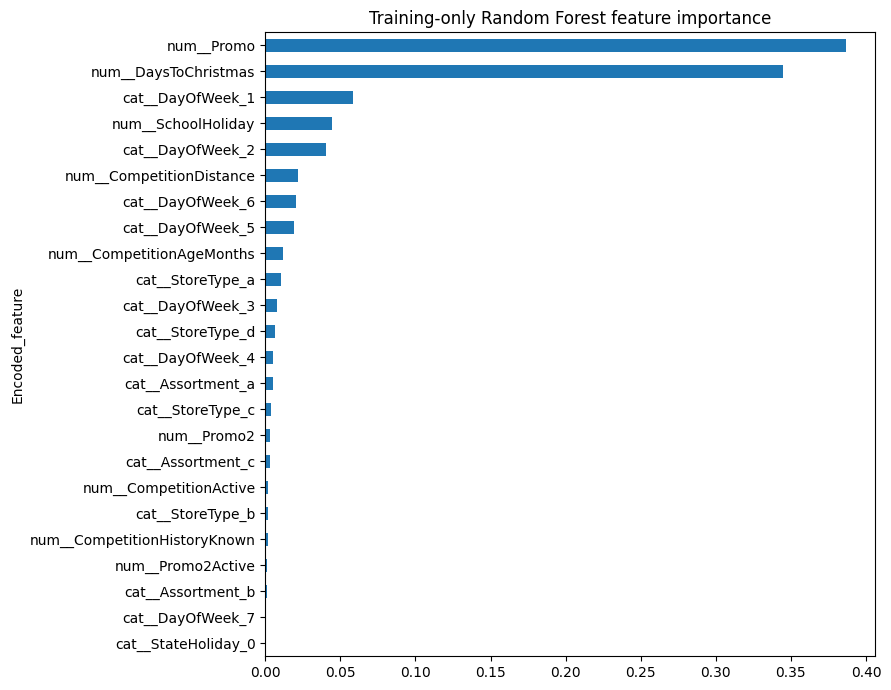


Review these validation results before final holdout testing.


In [57]:
# STEP 3 — FEATURE SELECTION AND MODEL COMPARISON

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, make_scorer,
    ConfusionMatrixDisplay, RocCurveDisplay
)

# ------------------------------------------------------------
# 1. Verify compatibility with the corrected Step 2
# ------------------------------------------------------------
assert set(christmas_open.loc[X_train.index, "Year"]) == {2013}, (
    "Rerun Step 2 with the corrected 2013/2014 split."
)
assert set(christmas_open.loc[X_test.index, "Year"]) == {2014}
assert christmas_open["Store_P75_Customers"].notna().all()
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert list(X_train.columns) == model_features

assert not {
    "Sales", "Customers", "Store_P75_Customers"
} & set(model_features), "A leakage variable is present."

# Local copies preserve the existing Step 2 variables.
train_dates = christmas_open.loc[
    X_train.index, "Date"
].reset_index(drop=True)

X_dev = X_train.reset_index(drop=True).copy()
y_dev = y_train.reset_index(drop=True).copy()

X_holdout = X_test.reset_index(drop=True).copy()
y_holdout = y_test.reset_index(drop=True).copy()

# ------------------------------------------------------------
# 2. Create expanding chronological validation folds in 2013
# All stores from the same date stay in the same time block.
# ------------------------------------------------------------
cv_splits = []
fold_rows = []

for train_end, valid_end in [(7, 12), (12, 17), (17, 24)]:
    train_indices = np.flatnonzero(
        train_dates.dt.day <= train_end
    )
    valid_indices = np.flatnonzero(
        (train_dates.dt.day > train_end)
        & (train_dates.dt.day <= valid_end)
    )

    assert len(train_indices) and len(valid_indices)
    assert (
        train_dates.iloc[train_indices].max()
        < train_dates.iloc[valid_indices].min()
    )
    assert (
        y_dev.iloc[train_indices].nunique()
        == y_dev.iloc[valid_indices].nunique()
        == 2
    )

    cv_splits.append((train_indices, valid_indices))

    fold_rows.append({
        "Training": f"1–{train_end} Dec 2013",
        "Validation": f"{train_end + 1}–{valid_end} Dec 2013",
        "Train rows": len(train_indices),
        "Validation rows": len(valid_indices)
    })

display(pd.DataFrame(fold_rows))

# ------------------------------------------------------------
# 3. Define evaluation metrics and model settings
# These settings are starting configurations, not tuned optima.
# ------------------------------------------------------------
scoring = {
    "Accuracy": "accuracy",
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": make_scorer(recall_score, zero_division=0),
    "F1": make_scorer(f1_score, zero_division=0),
    "ROC_AUC": "roc_auc"
}

estimators = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=30,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=12,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

# V2 keeps encoded columns whose Random Forest importance
# is at least the mean importance of all encoded columns.
selector = SelectFromModel(
    RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ),
    threshold="mean"
)

# ------------------------------------------------------------
# 4. Build model pipelines
# V1 = all features
# V2 = Random Forest feature selection
#
# clone(preprocessor) removes its previously fitted state.
# Each validation fold therefore fits its own preprocessing.
# ------------------------------------------------------------
candidates = {
    "Dummy baseline": Pipeline([
        ("prep", clone(preprocessor)),
        ("model", DummyClassifier(strategy="most_frequent"))
    ])
}

for name, estimator in estimators.items():
    for version in ["V1", "V2"]:
        steps = [("prep", clone(preprocessor))]

        if version == "V2":
            steps.append(("select", clone(selector)))

        steps.append(("model", clone(estimator)))
        candidates[f"{name} | {version}"] = Pipeline(steps)

# ------------------------------------------------------------
# 5. Evaluate candidates using ONLY 2013 validation folds
# ------------------------------------------------------------
cv_rows = []

for name, pipeline in candidates.items():
    print("Validating:", name, flush=True)

    scores = cross_validate(
        pipeline,
        X_dev,
        y_dev,
        cv=cv_splits,
        scoring=scoring,
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    row = {"Model": name}
    row.update({
        metric: scores[f"test_{metric}"].mean()
        for metric in scoring
    })
    row["F1_SD"] = scores["test_F1"].std()
    row["Train_F1"] = scores["train_F1"].mean()

    cv_rows.append(row)

cv_results = (
    pd.DataFrame(cv_rows)
    .set_index("Model")
    .sort_values(["F1", "ROC_AUC"], ascending=False)
)

print("\n2013 validation results:")
display(cv_results.round(4))

# Selection rule fixed before looking at 2014 results.
best_name = cv_results.drop(index="Dummy baseline").index[0]

print("\nSelected ML candidate:", best_name)
print("Selection criterion: validation F1, then ROC-AUC.")

if (
    cv_results.loc[best_name, "F1"]
    <= cv_results.loc["Dummy baseline", "F1"]
):
    print(
        "CAUTION: the selected ML model did not beat "
        "the dummy baseline on validation F1."
    )

# ------------------------------------------------------------
# 6. Document feature-selection decisions using 2013 only
# This audit does not change the validation results.
# ------------------------------------------------------------
selection_audit = clone(
    candidates["Random Forest | V2"]
).fit(X_dev, y_dev)

feature_selection = pd.DataFrame({
    "Encoded_feature": (
        selection_audit.named_steps["prep"].get_feature_names_out()
    ),
    "RF_importance": (
        selection_audit.named_steps["select"]
        .estimator_.feature_importances_
    ),
    "Retained_in_V2": (
        selection_audit.named_steps["select"].get_support()
    )
}).sort_values("RF_importance", ascending=False)

print("\nFeature-selection evidence — fitted on 2013 only:")
display(feature_selection)

feature_selection.sort_values("RF_importance").plot.barh(
    x="Encoded_feature",
    y="RF_importance",
    figsize=(9, 7),
    legend=False,
    title="Training-only Random Forest feature importance"
)
plt.tight_layout()
plt.show()

print("\nReview these validation results before final holdout testing.")

Christmas 2014 holdout results:


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Random Forest | V1,0.810,0.845,0.825,0.835,0.857
Dummy baseline,0.582,0.582,1.000,0.736,0.500
Random Forest | V2,0.808,0.842,0.826,0.834,0.881
Gradient Boosting | V2,0.853,0.852,0.905,0.878,0.897
Gradient Boosting | V1,0.821,0.845,0.848,0.846,0.900
Logistic Regression | V1,0.796,0.819,0.833,0.826,0.861
Logistic Regression | V2,0.781,0.793,0.843,0.817,0.864
Decision Tree | V1,0.815,0.854,0.823,0.838,0.890
Decision Tree | V2,0.853,0.852,0.905,0.878,0.910



Model selected before examining 2014: Random Forest | V1


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Random Forest | V1,0.810,0.845,0.825,0.835,0.857


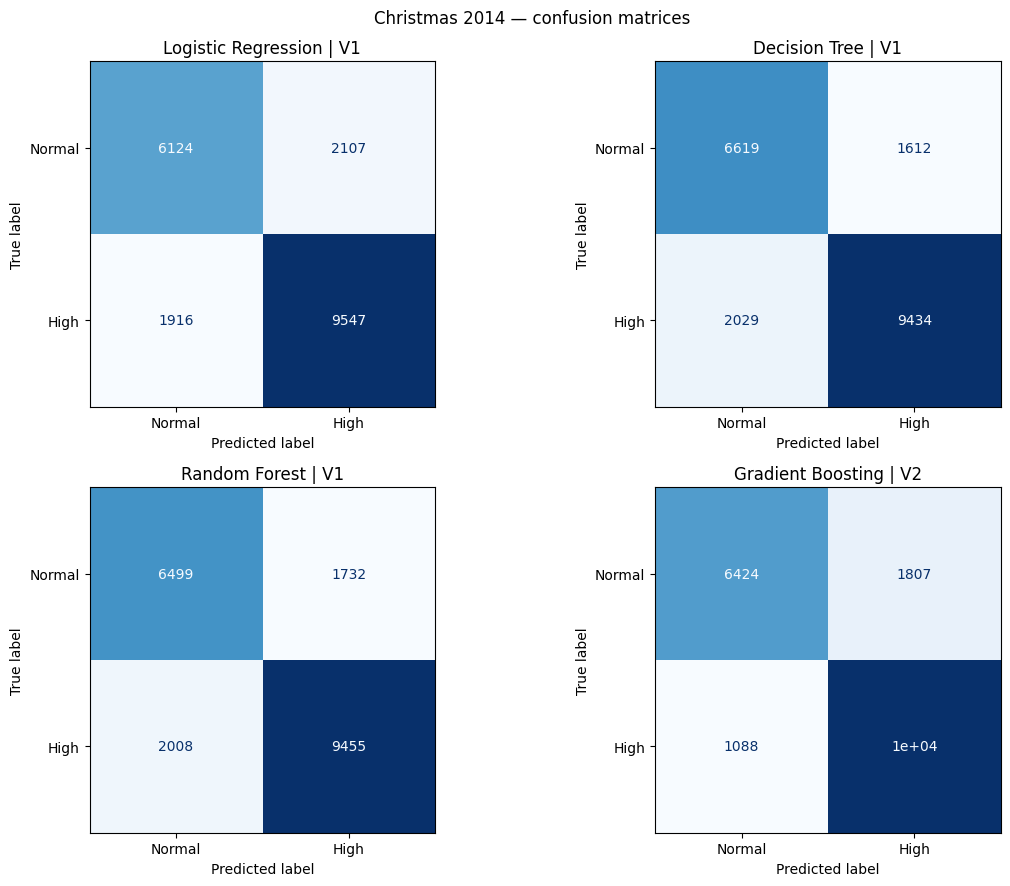

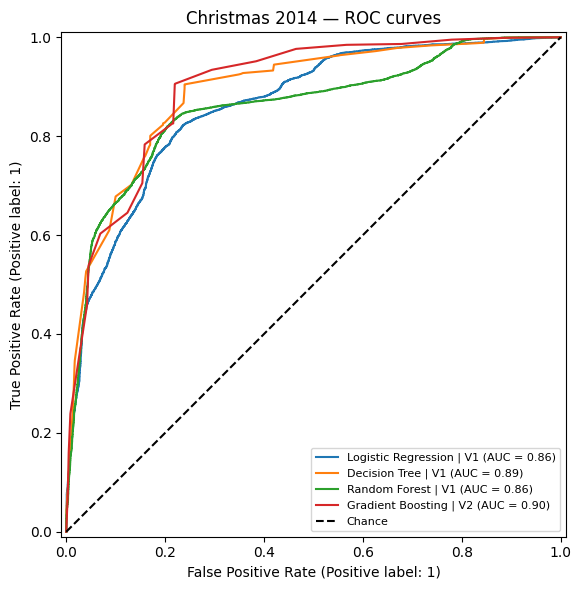

In [58]:
# STEP 3 — FINAL HOLDOUT EVALUATION
# Run after completing validation-based refinement.
# Do not use these results to repeatedly tune or reselect models.

fitted_models = {}
holdout_rows = []

for name, pipeline in candidates.items():
    fitted = clone(pipeline).fit(X_dev, y_dev)
    fitted_models[name] = fitted

    probability = fitted.predict_proba(X_holdout)[:, 1]
    predicted = (probability >= 0.5).astype(int)

    holdout_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_holdout, predicted),
        "Precision": precision_score(
            y_holdout, predicted, zero_division=0
        ),
        "Recall": recall_score(
            y_holdout, predicted, zero_division=0
        ),
        "F1": f1_score(
            y_holdout, predicted, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_holdout, probability)
    })

# Preserve validation ranking; do not re-rank to select using test data.
holdout_results = (
    pd.DataFrame(holdout_rows)
    .set_index("Model")
    .loc[cv_results.index]
)

print("Christmas 2014 holdout results:")
display(holdout_results.round(4))

best_model = fitted_models[best_name]

print("\nModel selected before examining 2014:", best_name)
display(holdout_results.loc[[best_name]].round(4))

# Each algorithm's best version, chosen using 2013 validation.
finalists = [
    next(
        candidate for candidate in cv_results.index
        if candidate.startswith(name + " |")
    )
    for name in estimators
]

# Confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for name, ax in zip(finalists, axes.ravel()):
    ConfusionMatrixDisplay.from_estimator(
        fitted_models[name],
        X_holdout,
        y_holdout,
        ax=ax,
        display_labels=["Normal", "High"],
        cmap="Blues",
        colorbar=False
    )
    ax.set_title(name)

fig.suptitle("Christmas 2014 — confusion matrices")
plt.tight_layout()
plt.show()

# ROC curves
fig, ax = plt.subplots(figsize=(9, 6))

for name in finalists:
    RocCurveDisplay.from_estimator(
        fitted_models[name],
        X_holdout,
        y_holdout,
        ax=ax,
        name=name
    )

ax.plot([0, 1], [0, 1], "k--", label="Chance")
ax.set_title("Christmas 2014 — ROC curves")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()